Перші 5 рядків датасету:
         area   distance  building_age    rent_price
0  108.705742  22.062638     27.691094  43341.775423
1   26.996732   1.897662     11.370401  20088.518925
2   48.646783  20.130976     34.770706  16054.042723
3   43.968335  21.804820     56.342813   9889.025094
4   42.867767   6.500354     17.944341  15194.148835

Розмір датасету: (500, 4)
Інформація про датасет:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area          500 non-null    float64
 1   distance      500 non-null    float64
 2   building_age  500 non-null    float64
 3   rent_price    500 non-null    float64
dtypes: float64(4)
memory usage: 15.8 KB

Пропущені значення:
area            0
distance        0
building_age    0
rent_price      0
dtype: int64

Типи змінних:
area            float64
distance        float64
building_age    float64
rent_price      float

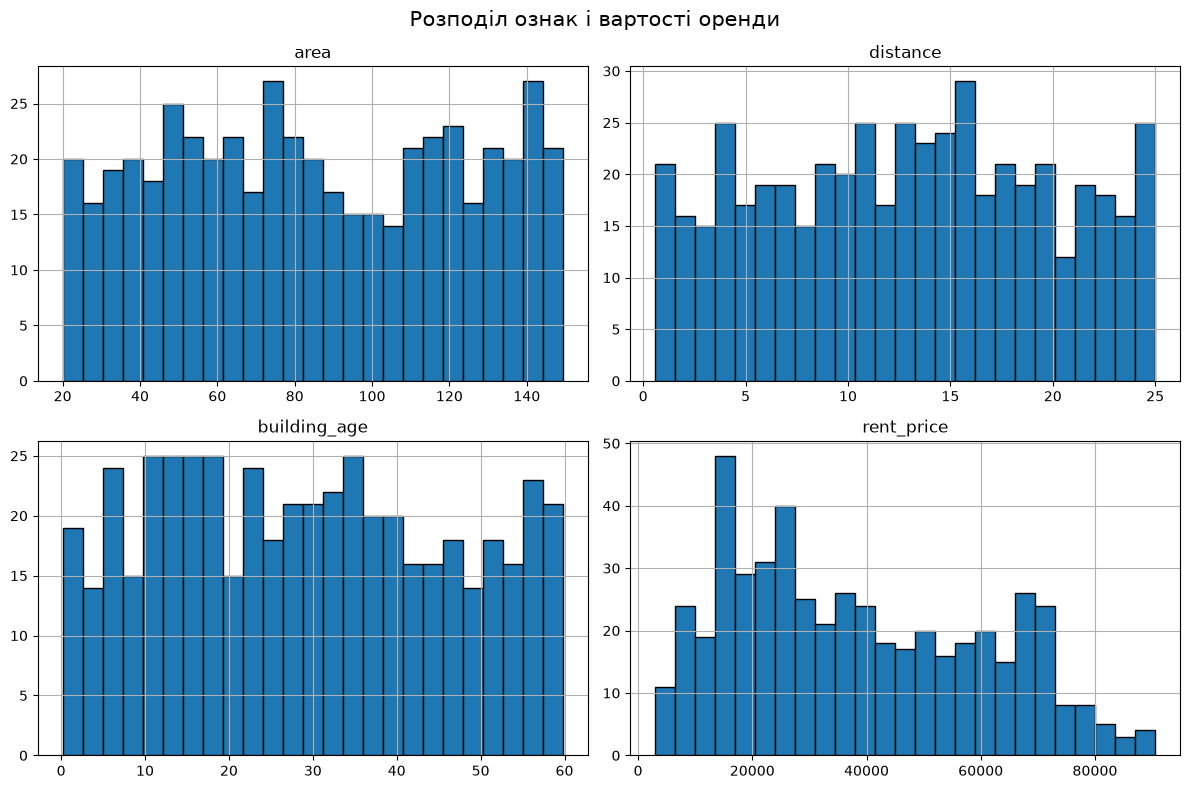

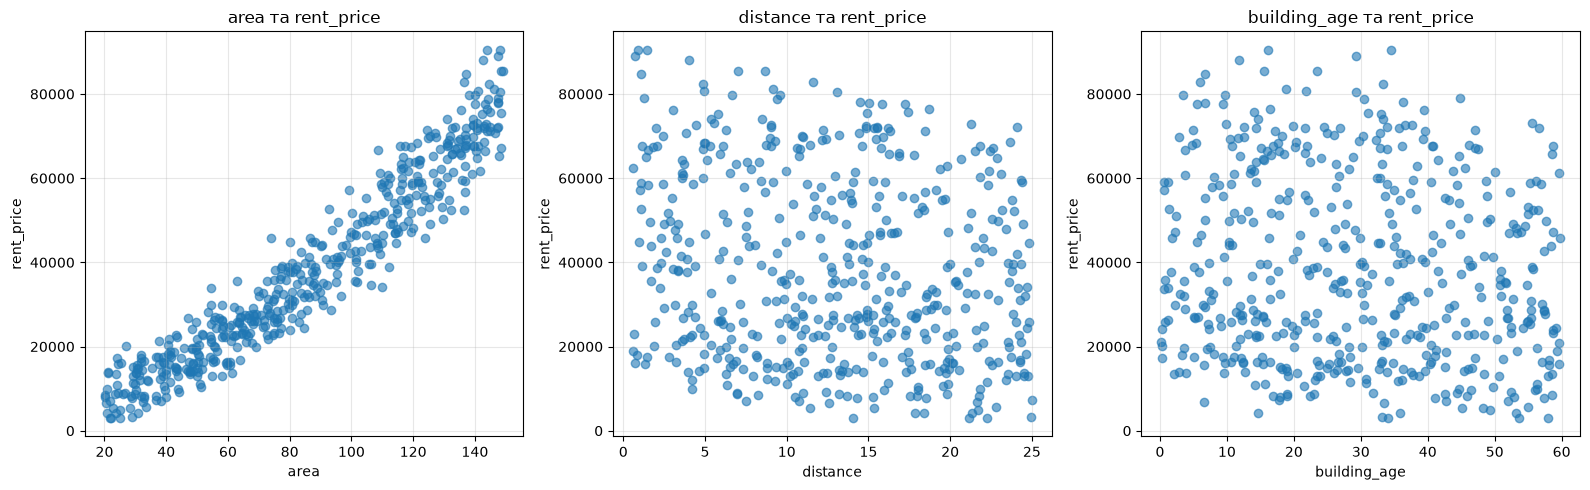

Розмір навчальної вибірки: (400, 3)
Розмір тестової вибірки: (100, 3)
Моделі успішно навчені!
Порівняння якості моделей:
                 Лінійна регресія  Поліноміальна регресія
R²                   9.658000e-01            9.858000e-01
Скоригований R²      9.647000e-01            9.843000e-01
MAE                  3.377638e+03            2.040558e+03
MSE                  1.653673e+07            6.879859e+06
RMSE                 4.066538e+03            2.622948e+03


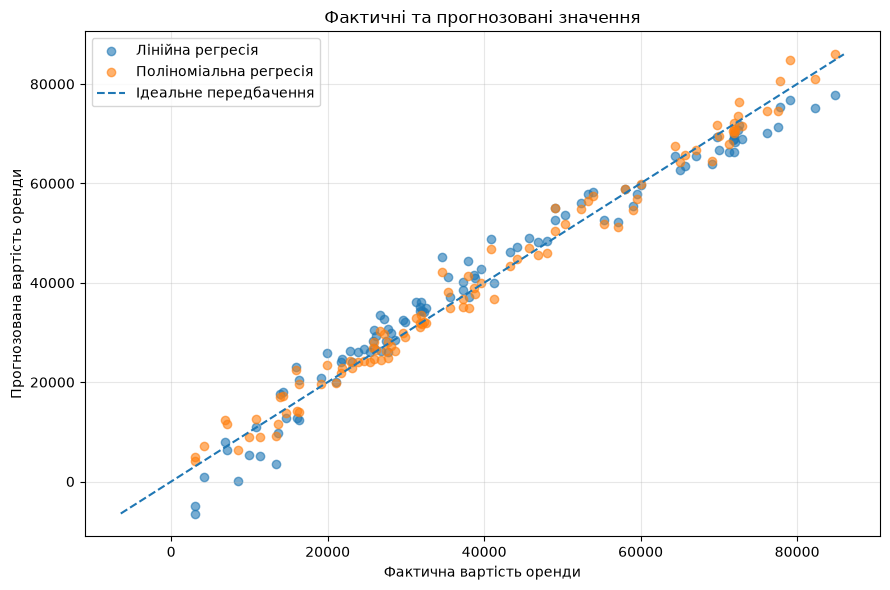

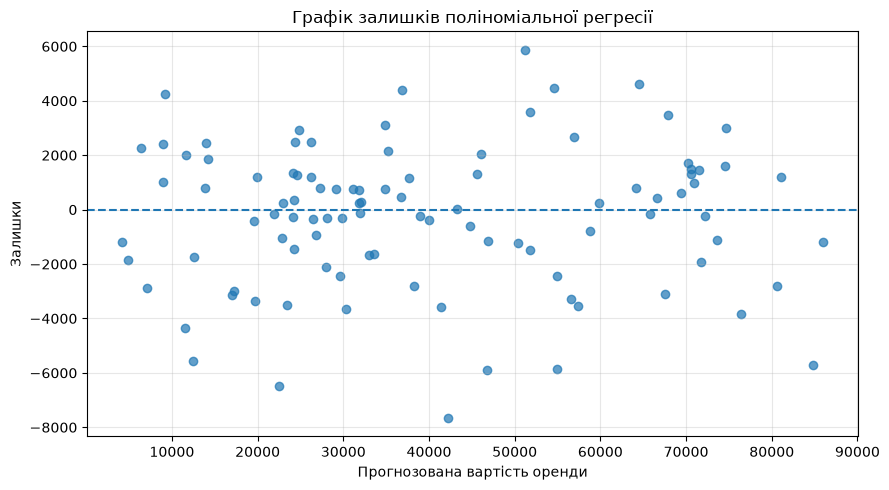

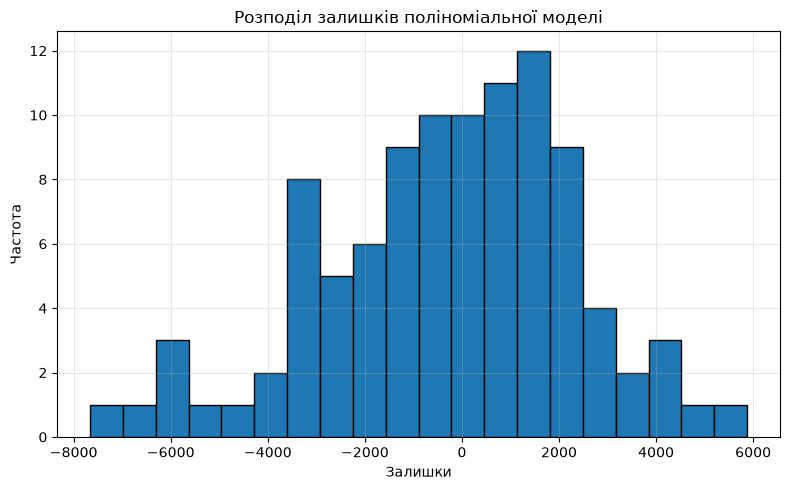

Середнє значення залишків: -260.302
Стандартне відхилення залишків: 2610.0003
Вільний член (intercept): 8947.3687

Коефіцієнти поліноміальної моделі:
               Ознака  Коефіцієнт
                 area    326.0939
             distance   -405.4176
         building_age   -158.5978
               area^2      1.8958
        area distance     -5.3101
    area building_age     -1.0770
           distance^2      9.8093
distance building_age      0.2422
       building_age^2      1.1955

Рівняння поліноміальної моделі:
rent_price = 8947.3687 + 326.0939 * area - 405.4176 * distance - 158.5978 * building_age + 1.8958 * area^2 - 5.3101 * area distance - 1.0770 * area building_age + 9.8093 * distance^2 + 0.2422 * distance building_age + 1.1955 * building_age^2
ПОРІВНЯННЯ МОДЕЛЕЙ
---------------------------------------------
R² лінійної моделі: 0.9658
R² поліноміальної моделі: 0.9858

RMSE лінійної моделі: 4066.54
RMSE поліноміальної моделі: 2622.95

ВИСНОВОК:
Поліноміальна регресія показала 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

df = pd.read_csv("apartment_rent_500.csv")

print("Перші 5 рядків датасету:")
print(df.head())

print("\nРозмір датасету:", df.shape)

print("Інформація про датасет:")
df.info()

print("\nПропущені значення:")
print(df.isnull().sum())

print("\nТипи змінних:")
print(df.dtypes)

print("\nОписова статистика:")
print(df.describe().round(2))

print("\nКількість дублікатів:", df.duplicated().sum())

df.hist(figsize=(12, 8), bins=25, edgecolor="black")

plt.suptitle("Розподіл ознак і вартості оренди", fontsize=15)
plt.tight_layout()
plt.show()

features = ["area", "distance", "building_age"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features):
    ax.scatter(df[feature], df["rent_price"], alpha=0.6)
    ax.set_xlabel(feature)
    ax.set_ylabel("rent_price")
    ax.set_title(f"{feature} та rent_price")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

X = df[["area", "distance", "building_age"]]
y = df["rent_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)
y_pred_poly = poly_model.predict(X_test)

print("Моделі успішно навчені!")

def calculate_metrics(y_true, y_pred, p):
    n = len(y_true)

    r2 = r2_score(y_true, y_pred)

    if n > p + 1:
        adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    else:
        adjusted_r2 = np.nan

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    return {
        "R²": r2,
        "Скоригований R²": adjusted_r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }

metrics_linear = calculate_metrics(
    y_test, y_pred_linear, p=3
)

metrics_poly = calculate_metrics(
    y_test, y_pred_poly, p=9
)

metrics_df = pd.DataFrame({
    "Лінійна регресія": metrics_linear,
    "Поліноміальна регресія": metrics_poly
})

print("Порівняння якості моделей:")
print(metrics_df.round(4))

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.6,
    label="Лінійна регресія"
)

plt.scatter(
    y_test,
    y_pred_poly,
    alpha=0.6,
    label="Поліноміальна регресія"
)

min_value = min(y_test.min(), y_pred_linear.min(), y_pred_poly.min())
max_value = max(y_test.max(), y_pred_linear.max(), y_pred_poly.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ідеальне передбачення"
)

plt.xlabel("Фактична вартість оренди")
plt.ylabel("Прогнозована вартість оренди")
plt.title("Фактичні та прогнозовані значення")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - y_pred_poly

# Графік залишків
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_poly,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Прогнозована вартість оренди")
plt.ylabel("Залишки")
plt.title("Графік залишків поліноміальної регресії")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Залишки")
plt.ylabel("Частота")
plt.title("Розподіл залишків поліноміальної моделі")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Середнє значення залишків:", round(residuals.mean(), 4))
print("Стандартне відхилення залишків:", round(residuals.std(), 4))

poly_features = poly_model.named_steps["polynomialfeatures"]
poly_regressor = poly_model.named_steps["linearregression"]

feature_names = poly_features.get_feature_names_out(X.columns)

coefficients = poly_regressor.coef_
intercept = poly_regressor.intercept_

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefficients
})

print("Вільний член (intercept):", round(intercept, 4))
print("\nКоефіцієнти поліноміальної моделі:")
print(coef_df.round(4).to_string(index=False))

equation = f"rent_price = {intercept:.4f}"

for name, coef in zip(feature_names, coefficients):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f} * {name}"

print("\nРівняння поліноміальної моделі:")
print(equation)

print("ПОРІВНЯННЯ МОДЕЛЕЙ")
print("-" * 45)

print(f"R² лінійної моделі: {metrics_linear['R²']:.4f}")
print(f"R² поліноміальної моделі: {metrics_poly['R²']:.4f}")

print(f"\nRMSE лінійної моделі: {metrics_linear['RMSE']:.2f}")
print(f"RMSE поліноміальної моделі: {metrics_poly['RMSE']:.2f}")

print("\nВИСНОВОК:")

if metrics_poly["RMSE"] < metrics_linear["RMSE"]:
    print(
        "Поліноміальна регресія показала меншу RMSE, "
        "тому вона точніше прогнозує орендну плату "
        "на тестовій вибірці."
    )
elif metrics_poly["RMSE"] > metrics_linear["RMSE"]:
    print(
        "Лінійна регресія показала меншу RMSE "
        "на тестовій вибірці."
    )
else:
    print("Обидві моделі показали однакову RMSE.")

if metrics_poly["R²"] > metrics_linear["R²"]:
    print(
        "Поліноміальна модель пояснює більшу частку "
        "варіації цільової змінної."
    )
elif metrics_poly["R²"] < metrics_linear["R²"]:
    print(
        "Лінійна модель має вище значення R² "
        "на тестовій вибірці."
    )
else:
    print("Моделі мають однакове значення R².")

